MLP R2: 0.27

MSE scores per fold: [0.51036886 0.53534911 0.59303734 0.52194932 0.55757806]
Average MSE and standard deviation: (0.544 +- 0.029)


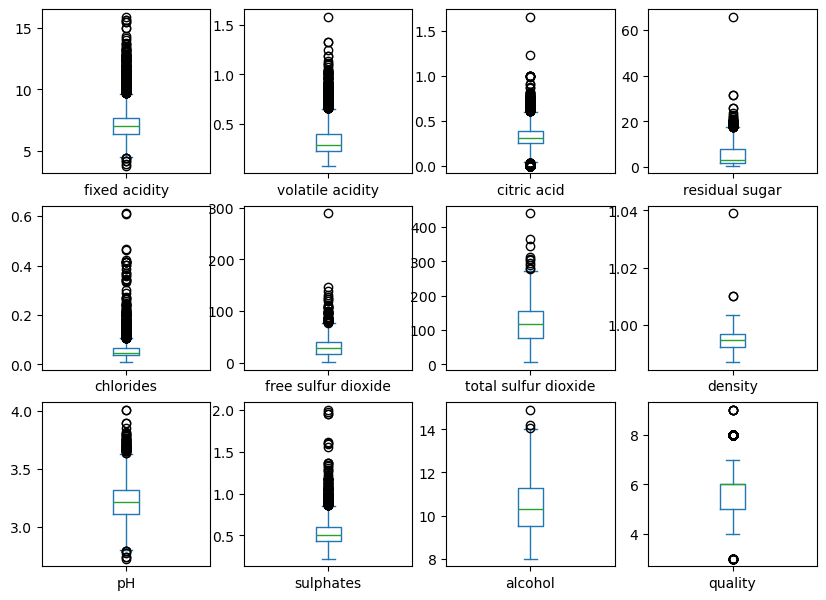

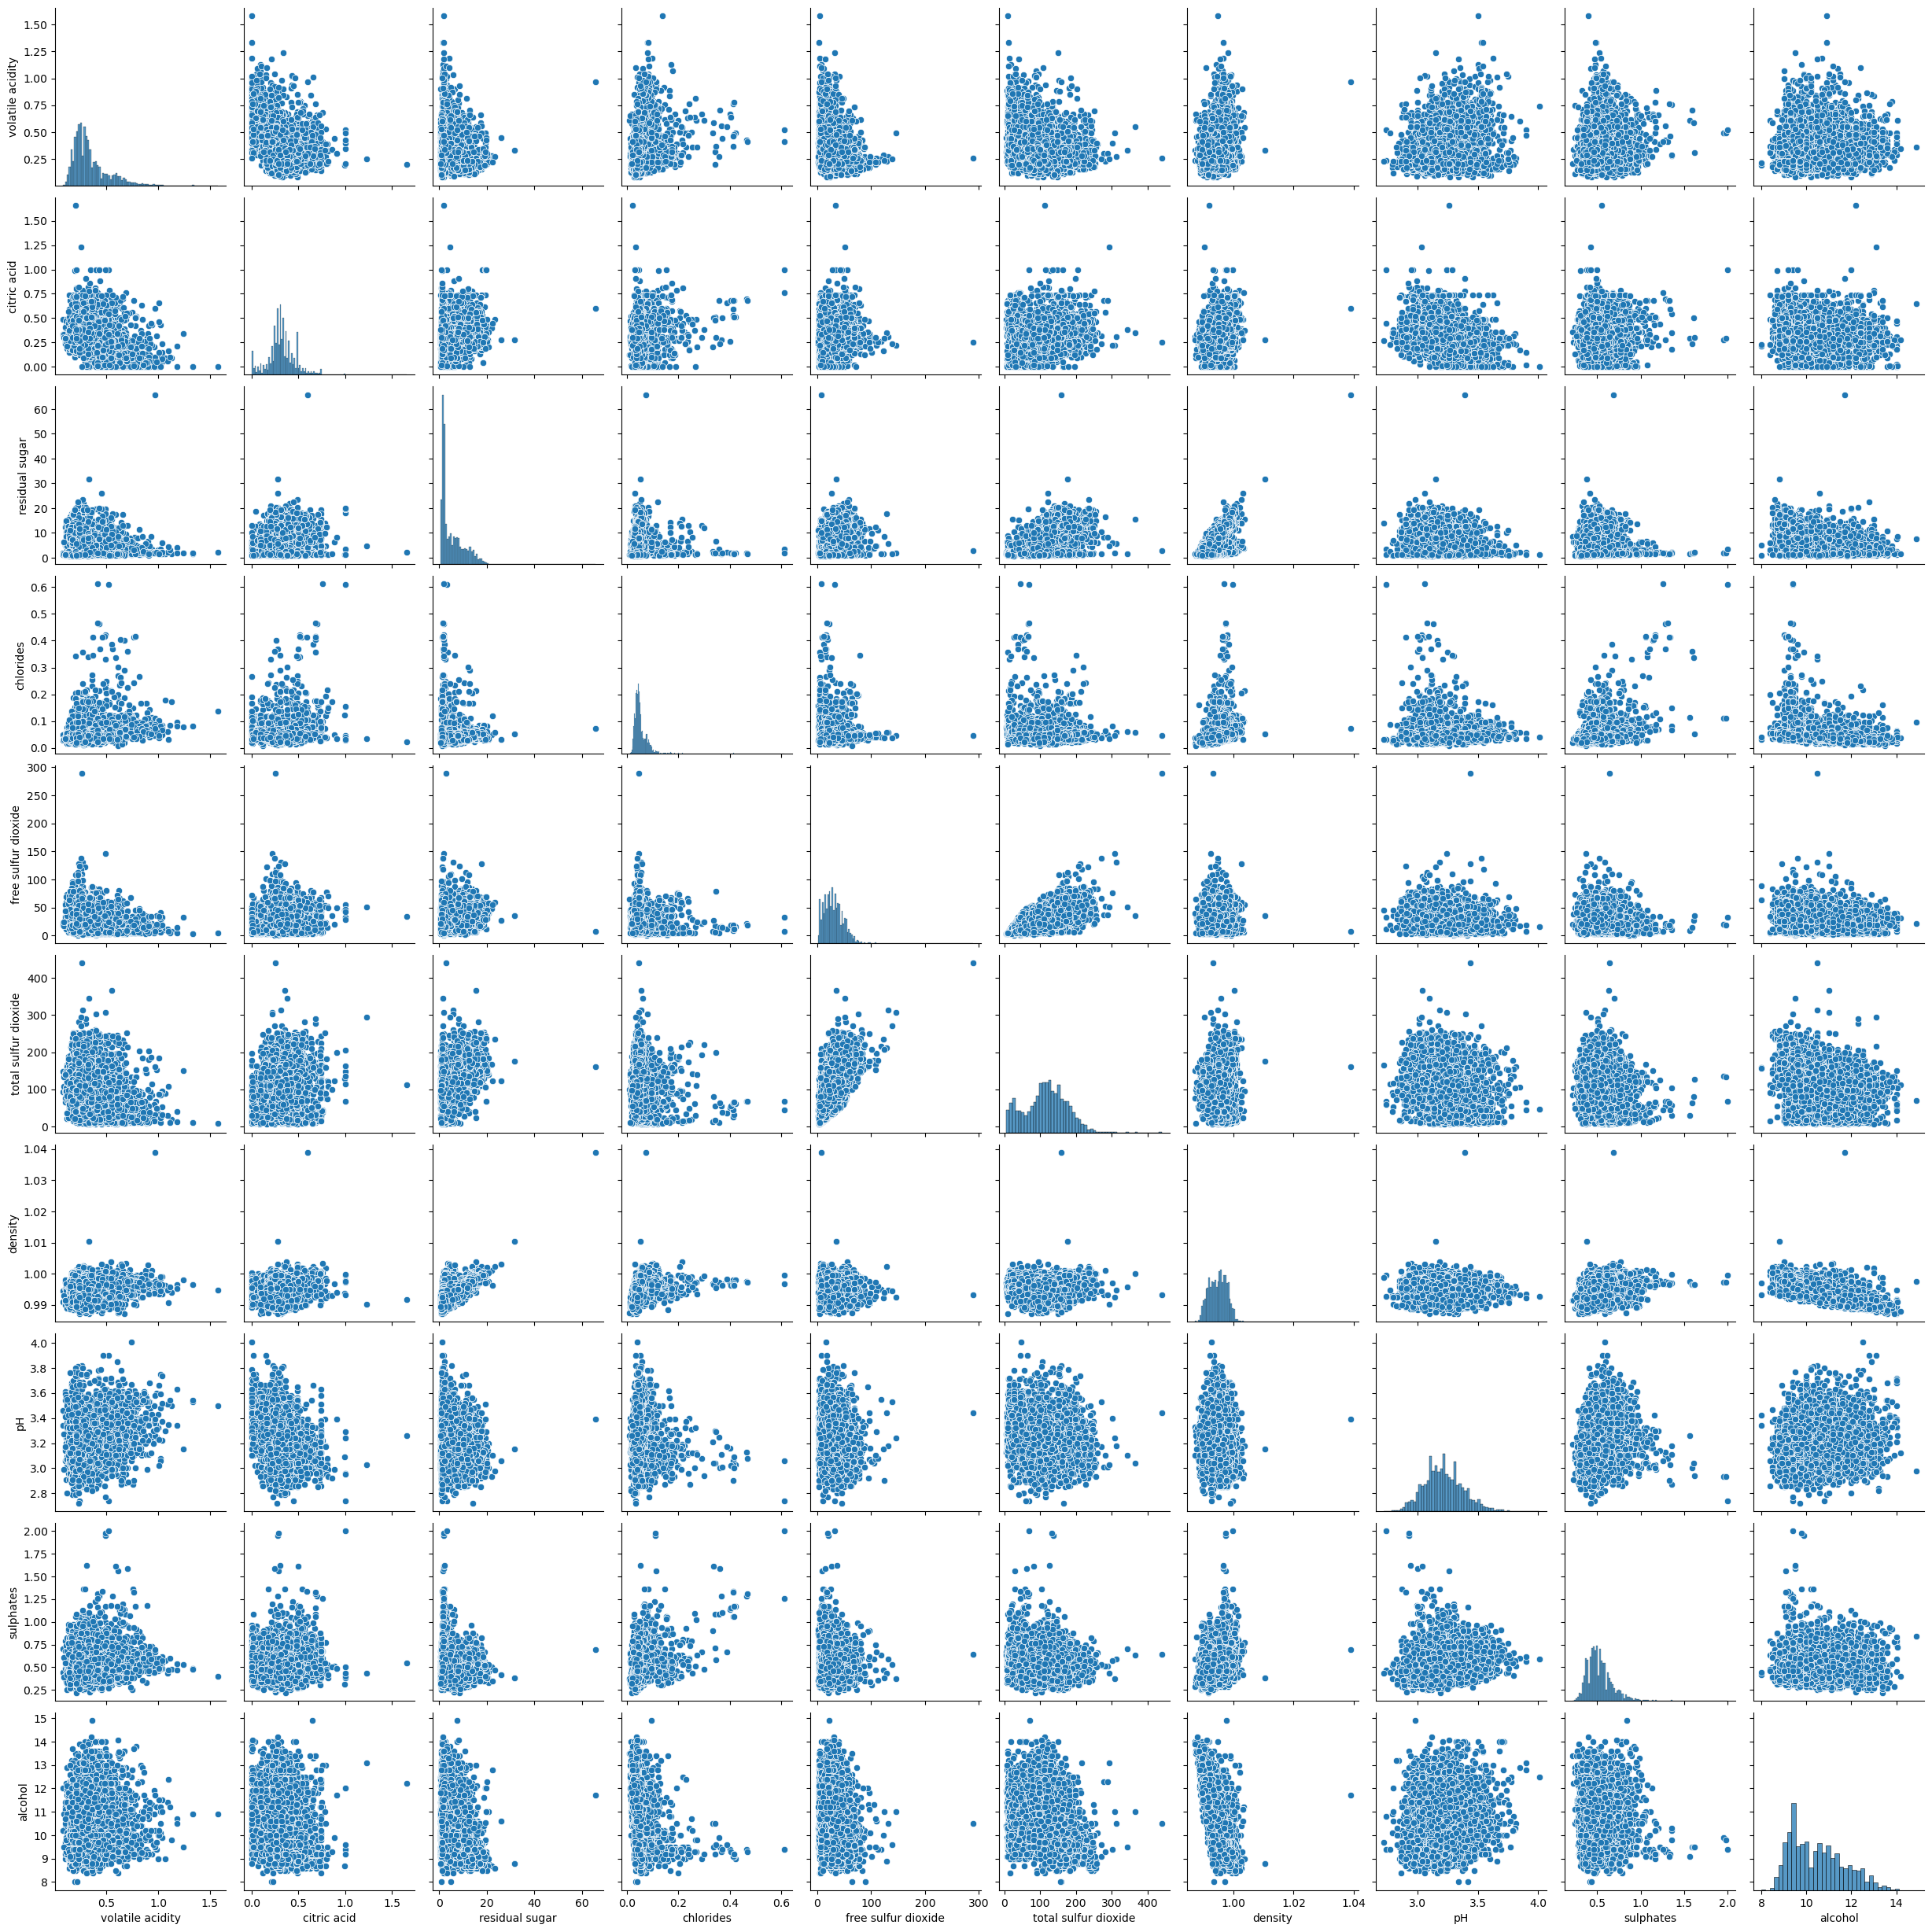

In [ ]:
#Regression Task
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

import matplotlib.pyplot as plt

from sklearn import datasets, linear_model
from sklearn import preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split

from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, cross_val_score


#read datasets
red_df=pd.read_csv('winequality-red.csv', index_col=False, sep= ";")
white_df=pd.read_csv('winequality-white.csv', index_col=False, sep=";")
#combine datasets
all_df = pd.concat([red_df, white_df], ignore_index = True)
all_df.head() 

#there are outliers in this dataset, use boxplots to find outliers
data_mean = all_df.iloc[:,:]
data_mean.plot(kind='box',subplots=True,layout=(8,4),sharex=False,sharey=False,fontsize=10,figsize=(10,20));

#visualise first 11 features with pairplot
sns.pairplot(all_df[list(all_df.columns[1:11])])

#we are predicting quality, so make quality into y
y = all_df["quality"]
X = all_df.drop(columns="quality")

num_col = X.select_dtypes("number").columns

norm_x = ColumnTransformer([("num",MinMaxScaler(), num_col)])

#create training and test datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=1)

X_train = norm_x.fit_transform(X_train)
X_test = norm_x.transform(X_test)

#implement MLP
mlp_reg = MLPRegressor(random_state=1, max_iter=300).fit(X_train, y_train)
print('MLP R2: {:03.2f}'.format(mlp_reg.score(X_test, y_test)))

#apply k-fold cross val
cv = KFold(n_splits=5, shuffle=True, random_state=1) #start w k=5

scores_reg = cross_val_score(mlp_reg, X, y, cv=cv, scoring="neg_mean_squared_error")
mse_scores = -scores_reg

print("\nMSE scores per fold:", mse_scores)
avg = (np.mean(mse_scores), np.std(mse_scores))

print("Average MSE and standard deviation: (%.3f +- %.3f)" % avg)



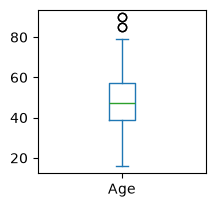

In [10]:
#Classification Task
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

import matplotlib.pyplot as plt

from sklearn import datasets, linear_model
from sklearn import preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.model_selection import train_test_split

from sklearn.neural_network import MLPRegressor, MLPClassifier

#read dataset
diabetes_df = pd.read_csv('diabetes_data_upload.csv',index_col=False)

#there are outliers in this dataset, use boxplots to find outliers
data_mean = diabetes_df.iloc[:,:]
data_mean.plot(kind='box',subplots=True,layout=(8,4),sharex=False,sharey=False,fontsize=10,figsize=(10,20));

#we are predicting class so can drop class col and make into y
y = LabelEncoder().fit_transform(diabetes_df["class"])
X = diabetes_df.drop(columns=["class"])

#separate column types into number and category
num_col = diabetes_df.select_dtypes("number").columns
cat_col = diabetes_df.select_dtypes(exclude="number").columns

pro_diabetes_df = ColumnTransformer([("num",MinMaxScaler(), num_col), ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"),cat_col)])






